# Entanglement Generation — Bell State — Qiskit Implementation

**Primitive:** Bell-state generation (maximal 2-qubit entanglement) via H + CNOT

**SETUP (assumed defaults — edit below if your report needs different values)**
- N QUBITS: 2
- GATE SEQUENCE: H(q0), then CX(control=q0, target=q1)
- QUBIT ORDERING: qubit 0 = rightmost bit in printed bitstring (Qiskit's native convention)
- SHOTS: 10000, SEED: 42
- GLOBAL PHASE: normalized so first nonzero amplitude (ascending bitstring order) is real and positive
- Basis ordering for matrices: {|00>, |01>, |10>, |11>} (ascending binary order)

**Theory recap:** Starting from |00>, applying a Hadamard to qubit 0 creates the
superposition (|00> + |01>)/sqrt(2) (using qubit0-rightmost notation). Applying CX with
qubit 0 as control and qubit 1 as target then flips qubit 1 whenever qubit 0 is |1>,
producing the maximally entangled Bell state

|Phi+> = (|00> + |11>) / sqrt(2)

Neither qubit has a definite state on its own -- measuring one instantly determines the
other, which is the defining signature of entanglement.

H = (1/sqrt(2)) [[1, 1], [1, -1]]

CX (control=q0, target=q1) is a controlled-NOT: flips the target's amplitude pairs
conditioned on the control being |1>.

**IMPORTANT: Run every cell in order, top to bottom** (Kernel -> Restart & Run All).

In [1]:
# Run this cell first if you get ModuleNotFoundError or MissingOptionalLibraryError.
# pylatexenc is required for circuit.draw(output="mpl") gate-label rendering -- not pulled in
# automatically by the base qiskit install, so it must be listed explicitly.
!pip install -q qiskit qiskit-aer pylatexenc
# Restart the kernel after this finishes (Kernel -> Restart Kernel), then Run All.


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 4.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 56.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 69.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 74.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 4.0 MB/s eta 0:00:00


In [2]:
# --- Imports ---
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# --- SETUP constants (all cells below use these -- defined once, here) ---
N_QUBITS = 2
SHOTS = 10000
SEED = 42

print(f"N_QUBITS={N_QUBITS}, SHOTS={SHOTS}, SEED={SEED}")
print("Gate sequence: H(q0) -> CX(control=q0, target=q1)")

N_QUBITS=2, SHOTS=10000, SEED=42
Gate sequence: H(q0) -> CX(control=q0, target=q1)


## 1. Build the circuit explicitly, gate by gate

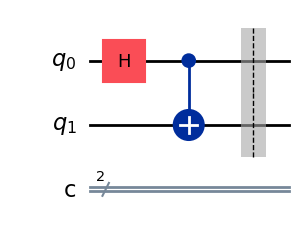

In [3]:
qc = QuantumCircuit(N_QUBITS, N_QUBITS, name="bell_state")

qc.h(0)      # Put qubit 0 into an equal superposition of |0> and |1>
qc.cx(0, 1)  # Entangling step: flip qubit 1 whenever qubit 0 is |1>, correlating the two qubits

qc.barrier()
qc.draw(output="mpl")

## 2. Draw the circuit and save to file

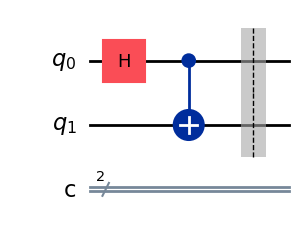

In [12]:
fig = qc.draw(output="mpl")
fig.savefig("bell_state_qiskit_circuit.png", bbox_inches="tight")
fig

## 3. Explicit matrix representation of the key operator(s)

In [4]:
# --- (a) Hand-built matrices in NumPy, using Qiskit's little-endian basis {|00>,|01>,|10>,|11>} ---
I2 = np.eye(2, dtype=complex)
H_gate = (1 / np.sqrt(2)) * np.array([[1, 1],
                                       [1, -1]], dtype=complex)

print("H matrix:")
print(np.round(H_gate, 4))

# H applied to qubit 0 only -> full_op = kron(gate_on_q1, gate_on_q0) = kron(I, H)
# (same tensor-product convention used for independent single-qubit gates: qubit 0 rightmost)
H_full = np.kron(I2, H_gate)
print("\nH(q0) lifted to the full 2-qubit space (kron(I, H)):")
print(np.round(H_full, 4))

# CX matrix, control=q0 (LSB/rightmost), target=q1 (MSB/leftmost), in basis {|00>,|01>,|10>,|11>}
CX_matrix = np.array([
    [1, 0, 0, 0],
    [0, 0, 0, 1],
    [0, 0, 1, 0],
    [0, 1, 0, 0],
], dtype=complex)
print("\nCX matrix (control=q0, target=q1):")
print(np.round(CX_matrix, 4))

# Full circuit unitary: CX applied AFTER H, so U = CX @ H_full
U_hand = CX_matrix @ H_full
print("\nFull circuit unitary U = CX . H_full (hand-built):")
print(np.round(U_hand, 4))

H matrix:
[[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]

H(q0) lifted to the full 2-qubit space (kron(I, H)):
[[ 0.7071+0.j  0.7071+0.j  0.    +0.j  0.    +0.j]
 [ 0.7071+0.j -0.7071+0.j  0.    +0.j -0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j  0.7071+0.j]
 [ 0.    +0.j -0.    +0.j  0.7071+0.j -0.7071+0.j]]

CX matrix (control=q0, target=q1):
[[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 1.+0.j]
 [0.+0.j 0.+0.j 1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j 0.+0.j 0.+0.j]]

Full circuit unitary U = CX . H_full (hand-built):
[[ 0.7071+0.j  0.7071+0.j  0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j -0.7071+0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j  0.    +0.j  0.    +0.j]]


In [5]:
# --- (b) Cross-check against Qiskit's own Operator extraction ---
# Operator() safely ignores barrier instructions, so qc (h + cx + barrier, no measurements
# yet at this point in the notebook) can be used directly -- no need for a second circuit.
full_op = Operator(qc)

print(f"Full {2**2}x{2**2} operator from Qiskit's Operator(qc) (basis {{|00>, |01>, |10>, |11>}}):")
print(np.round(full_op.data, 4))

matches = np.allclose(full_op.data, U_hand, atol=1e-8)
print(f"\nHand-built matrix matches Qiskit's Operator extraction: {matches}")
assert matches, "Hand-built matrix and Qiskit Operator disagree -- check gate/basis conventions!"

Full 4x4 operator from Qiskit's Operator(qc) (basis {|00>, |01>, |10>, |11>}):
[[ 0.7071+0.j  0.7071+0.j  0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j -0.7071+0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j  0.    +0.j  0.    +0.j]]

Hand-built matrix matches Qiskit's Operator extraction: True


## 4. Exact statevector (before measurement), global-phase normalized

In [6]:
sv = Statevector.from_instruction(qc)  # qc has no measurements yet at this point -- safe to use directly
amps = sv.data.copy()

def normalize_global_phase(statevector_data, n_qubits):
    dim = 2 ** n_qubits
    bitstrings = [format(i, f"0{n_qubits}b") for i in range(dim)]
    order = np.argsort(bitstrings)
    for idx in order:
        amp = statevector_data[idx]
        if abs(amp) > 1e-9:
            phase = np.angle(amp)
            corrected = statevector_data * np.exp(-1j * phase)
            return corrected, bitstrings
    return statevector_data, bitstrings

amps_norm, bitstrings = normalize_global_phase(amps, N_QUBITS)

exact_probs = {}
for i, bs in enumerate(bitstrings):
    exact_probs[bs] = round(abs(amps_norm[i]) ** 2, 4)

exact_probs = dict(sorted(exact_probs.items()))
print("Exact statevector amplitudes (phase-normalized):")
print(np.round(amps_norm, 4))
print()
print("Exact statevector probabilities (qubit0 = rightmost):")
print(exact_probs)

Exact statevector amplitudes (phase-normalized):
[0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j]

Exact statevector probabilities (qubit0 = rightmost):
{'00': np.float64(0.5), '01': np.float64(0.0), '10': np.float64(0.0), '11': np.float64(0.5)}


**Ordering note:** Qiskit's `Statevector` already indexes amplitudes with qubit 0 as the
least-significant (rightmost) bit of the binary index -- matches the SETUP convention
directly, so no reversal was needed here.

**Phase note:** For this circuit the amplitudes are already real and positive
(1/sqrt(2) each on |00> and |11>), so the global-phase normalization step above is a
no-op -- included for consistency with the CUDA-Q notebook and other primitives, not
because it changes anything here.

## 5. Measurement: add measurements, run AerSimulator, plot histogram

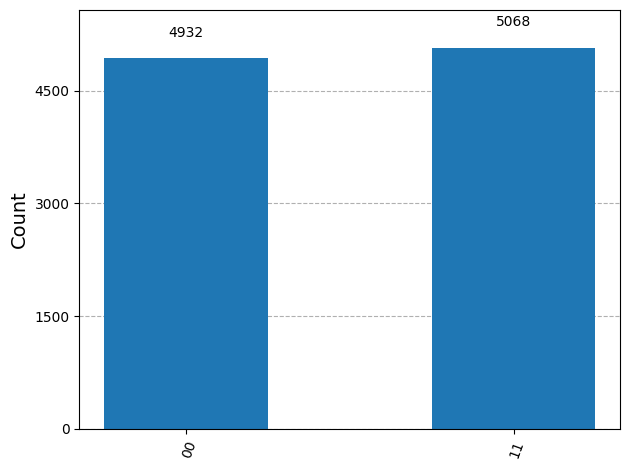

In [7]:
qc_measured = qc.copy()
qc_measured.measure(range(N_QUBITS), range(N_QUBITS))

sim = AerSimulator(seed_simulator=SEED)
job = sim.run(qc_measured, shots=SHOTS, seed_simulator=SEED)
result = job.result()
counts = result.get_counts()

fig2 = plot_histogram(counts)
fig2.savefig("bell_state_qiskit_histogram.png", bbox_inches="tight")
fig2

In [8]:
sampled_probs = {bs: round(c / SHOTS, 4) for bs, c in counts.items()}
sampled_probs = dict(sorted(sampled_probs.items()))
print(f"Sampled probabilities ({SHOTS} shots, seed={SEED}):")
print(sampled_probs)

Sampled probabilities (10000 shots, seed=42):
{'00': 0.4932, '11': 0.5068}


## 6. Circuit resource counts

In [9]:
print(f"Depth: {qc_measured.depth()}")
print(f"Gate/operation count: {qc_measured.size()}")

Depth: 3
Gate/operation count: 4


## 7. Convention notes

In [10]:
print("Bit ordering: Qiskit's Statevector and get_counts() both natively use qubit 0 as the")
print("rightmost (least-significant) bit of the printed bitstring, matching this notebook's")
print("SETUP convention exactly -> NO reversal applied.")
print()
print("Global phase: normalized by finding the first nonzero amplitude in ascending-bitstring")
print("order and rotating the whole statevector so that amplitude becomes real and positive.")
print("For the Bell state this is a no-op -- the |00> and |11> amplitudes are already real and")
print("positive (1/sqrt(2) each) -- unlike the Arbitrary States primitive, which had genuinely")
print("complex amplitudes.")
print()
print("Entanglement check: the two qubits are NOT independent -- the full statevector cannot be")
print("written as a tensor product of two single-qubit states (unlike Basic States/Superposition/")
print("Arbitrary States, which were all separable). This is the defining feature of this primitive.")

Bit ordering: Qiskit's Statevector and get_counts() both natively use qubit 0 as the
rightmost (least-significant) bit of the printed bitstring, matching this notebook's
SETUP convention exactly -> NO reversal applied.

Global phase: normalized by finding the first nonzero amplitude in ascending-bitstring
order and rotating the whole statevector so that amplitude becomes real and positive.
For the Bell state this is a no-op -- the |00> and |11> amplitudes are already real and
positive (1/sqrt(2) each) -- unlike the Arbitrary States primitive, which had genuinely
complex amplitudes.

Entanglement check: the two qubits are NOT independent -- the full statevector cannot be
written as a tensor product of two single-qubit states (unlike Basic States/Superposition/
Arbitrary States, which were all separable). This is the defining feature of this primitive.


## Final result (for diffing against the CUDA-Q version)

In [11]:
QISKIT_RESULT = exact_probs
print("QISKIT_RESULT =", QISKIT_RESULT)

QISKIT_RESULT = {'00': np.float64(0.5), '01': np.float64(0.0), '10': np.float64(0.0), '11': np.float64(0.5)}
